# Gesture-Controlled Photo Booth: Hyperparameter Tuning, `degrees`
**IAT 360 Computer Vision Project, Group 6.** Proposed for **Daffodil Ho**.

Each group member changes one hyperparameter of the baseline (`Gesture_YOLO_Baseline.ipynb`) to three other values and compares against it. This hyperparameter is **`degrees`**, random rotation of the training images: each training image is rotated by a random angle between −`degrees` and +`degrees`, and its boxes are moved with it.

| Run | degrees | Everything else |
|---|---|---|
| **Baseline** | **0** (no rotation, Ultralytics default) | YOLOv8s (COCO), SGD lr0 0.01, 50 epochs, patience 15, batch 16, imgsz 640, seed 0, deterministic |
| degrees_10 | ±10° | same as baseline |
| degrees_20 | ±20° | same as baseline |
| degrees_30 | ±30° | same as baseline |

**Why `degrees`.** HaGRID hands are mostly upright: one person facing a phone camera and holding the gesture straight. In our own photos, people hold their hands at an angle, across the body or raised to the side, and tilted hands are one of the failure types in the baseline's error analysis. Rotation augmentation shows the model tilted versions of every training hand without collecting new photos.

**Hypothesis.** Some rotation (10-20°) should raise recall on our photos, because tilted hands look more like what the model saw in training. Too much rotation has two costs:
- **like vs dislike.** A thumbs-up and a thumbs-down differ mainly in which way the thumb points. Rotation up to 30° keeps the thumb clearly up or down (this is also why `flipud` stays 0), but the larger values move the two classes closer together, so we check the like↔dislike confusions in section 3.1.
- **Looser boxes.** Ultralytics rotates the four corners of each box and takes a new upright box around them, so a rotated hand gets a box larger than the hand. Training on these looser boxes can lower box precision, which would show up in mAP50-95 more than in mAP50.

Validation is HaGRID (mostly upright hands), so we expect it to change little; the team photos are the real test.

In [1]:
import json, shutil
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from ultralytics import YOLO

from gesture_eval import BASELINE, CLASSES, evaluate, error_analysis, summary_row, train_info

ROOT = Path.cwd()          # run this notebook from the repo root
assert (ROOT / "data.yaml").exists(), "Open the notebook from the repo root"
pd.set_option("display.precision", 3)
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

torch 2.11.0+cu128 | NVIDIA GeForce RTX 5060 Ti


## 1. Train the three `degrees` variants
Identical to the baseline except `degrees`. Each run's best checkpoint is copied to `models/degrees_<value>_best.pt`, and its training history and a batch of augmented training images to `results/degrees_<value>/`. A run that is already saved is skipped, so the notebook can be re-run for evaluation only.

In [2]:
VALUES = [10, 20, 30]

for v in VALUES:
    name = f"degrees_{v}"
    out, weights = ROOT / "results" / name, ROOT / "models" / f"{name}_best.pt"
    if weights.exists():
        print(f"{name}: already trained -> {weights.name}")
        continue
    hp = {**BASELINE, "degrees": v}
    model = YOLO("yolov8s.pt")
    model.train(**hp, project=str(ROOT / "runs"), name=name, exist_ok=True)
    run = Path(model.trainer.save_dir)
    out.mkdir(parents=True, exist_ok=True)
    shutil.copy2(run / "weights" / "best.pt", weights)
    for f in ["results.csv", "results.png", "args.yaml", "train_batch0.jpg"]:
        if (run / f).exists():
            shutil.copy2(run / f, out / f)
    info = train_info(run / "results.csv")
    (out / "metrics.json").write_text(json.dumps(
        {"model": "yolov8s.pt (COCO-pretrained) fine-tuned", "changed": {"degrees": v},
         "hyperparameters": hp, **info}, indent=2))
    print(f"{name}: {info}")
    del model; torch.cuda.empty_cache()

degrees_10: already trained -> degrees_10_best.pt
New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=20, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.

### 1.1 What the model trains on
A batch of augmented training images from the ±30° run (`train_batch0.jpg`, saved by Ultralytics): the rotated images and the upright boxes around the rotated hands. (The tiling into four is mosaic, which every run, including the baseline, uses.)

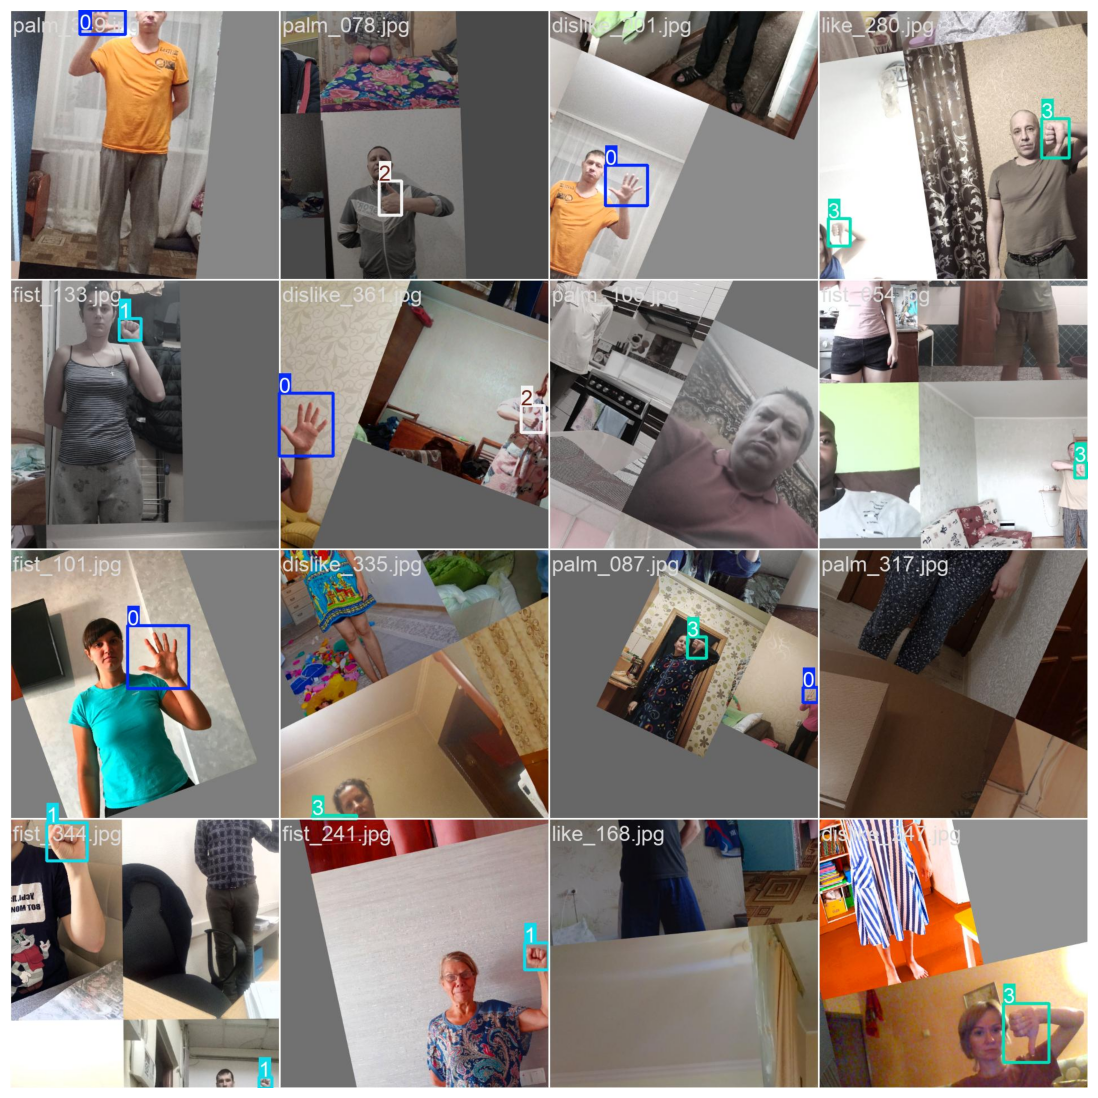

In [3]:
plt.figure(figsize=(14, 14)); plt.imshow(plt.imread(ROOT / "results" / "degrees_30" / "train_batch0.jpg")); plt.axis("off"); plt.show()

### 1.2 Training curves
Validation mAP50-95 per epoch (dots mark the kept checkpoint), plus each run's Ultralytics `results.png`.

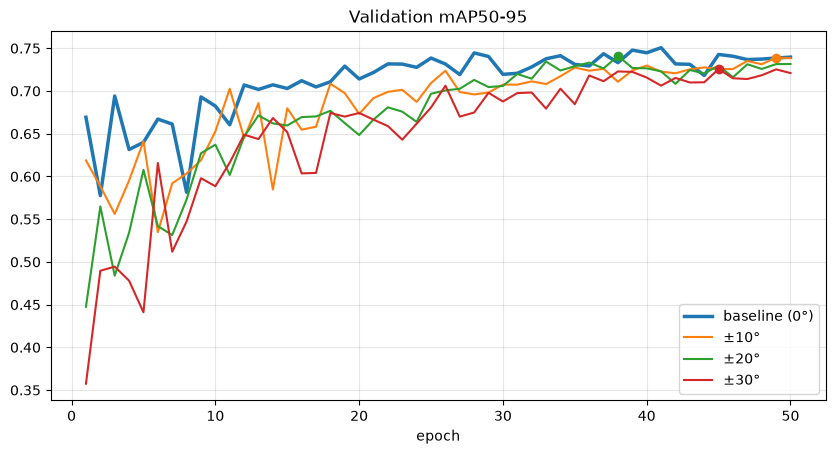

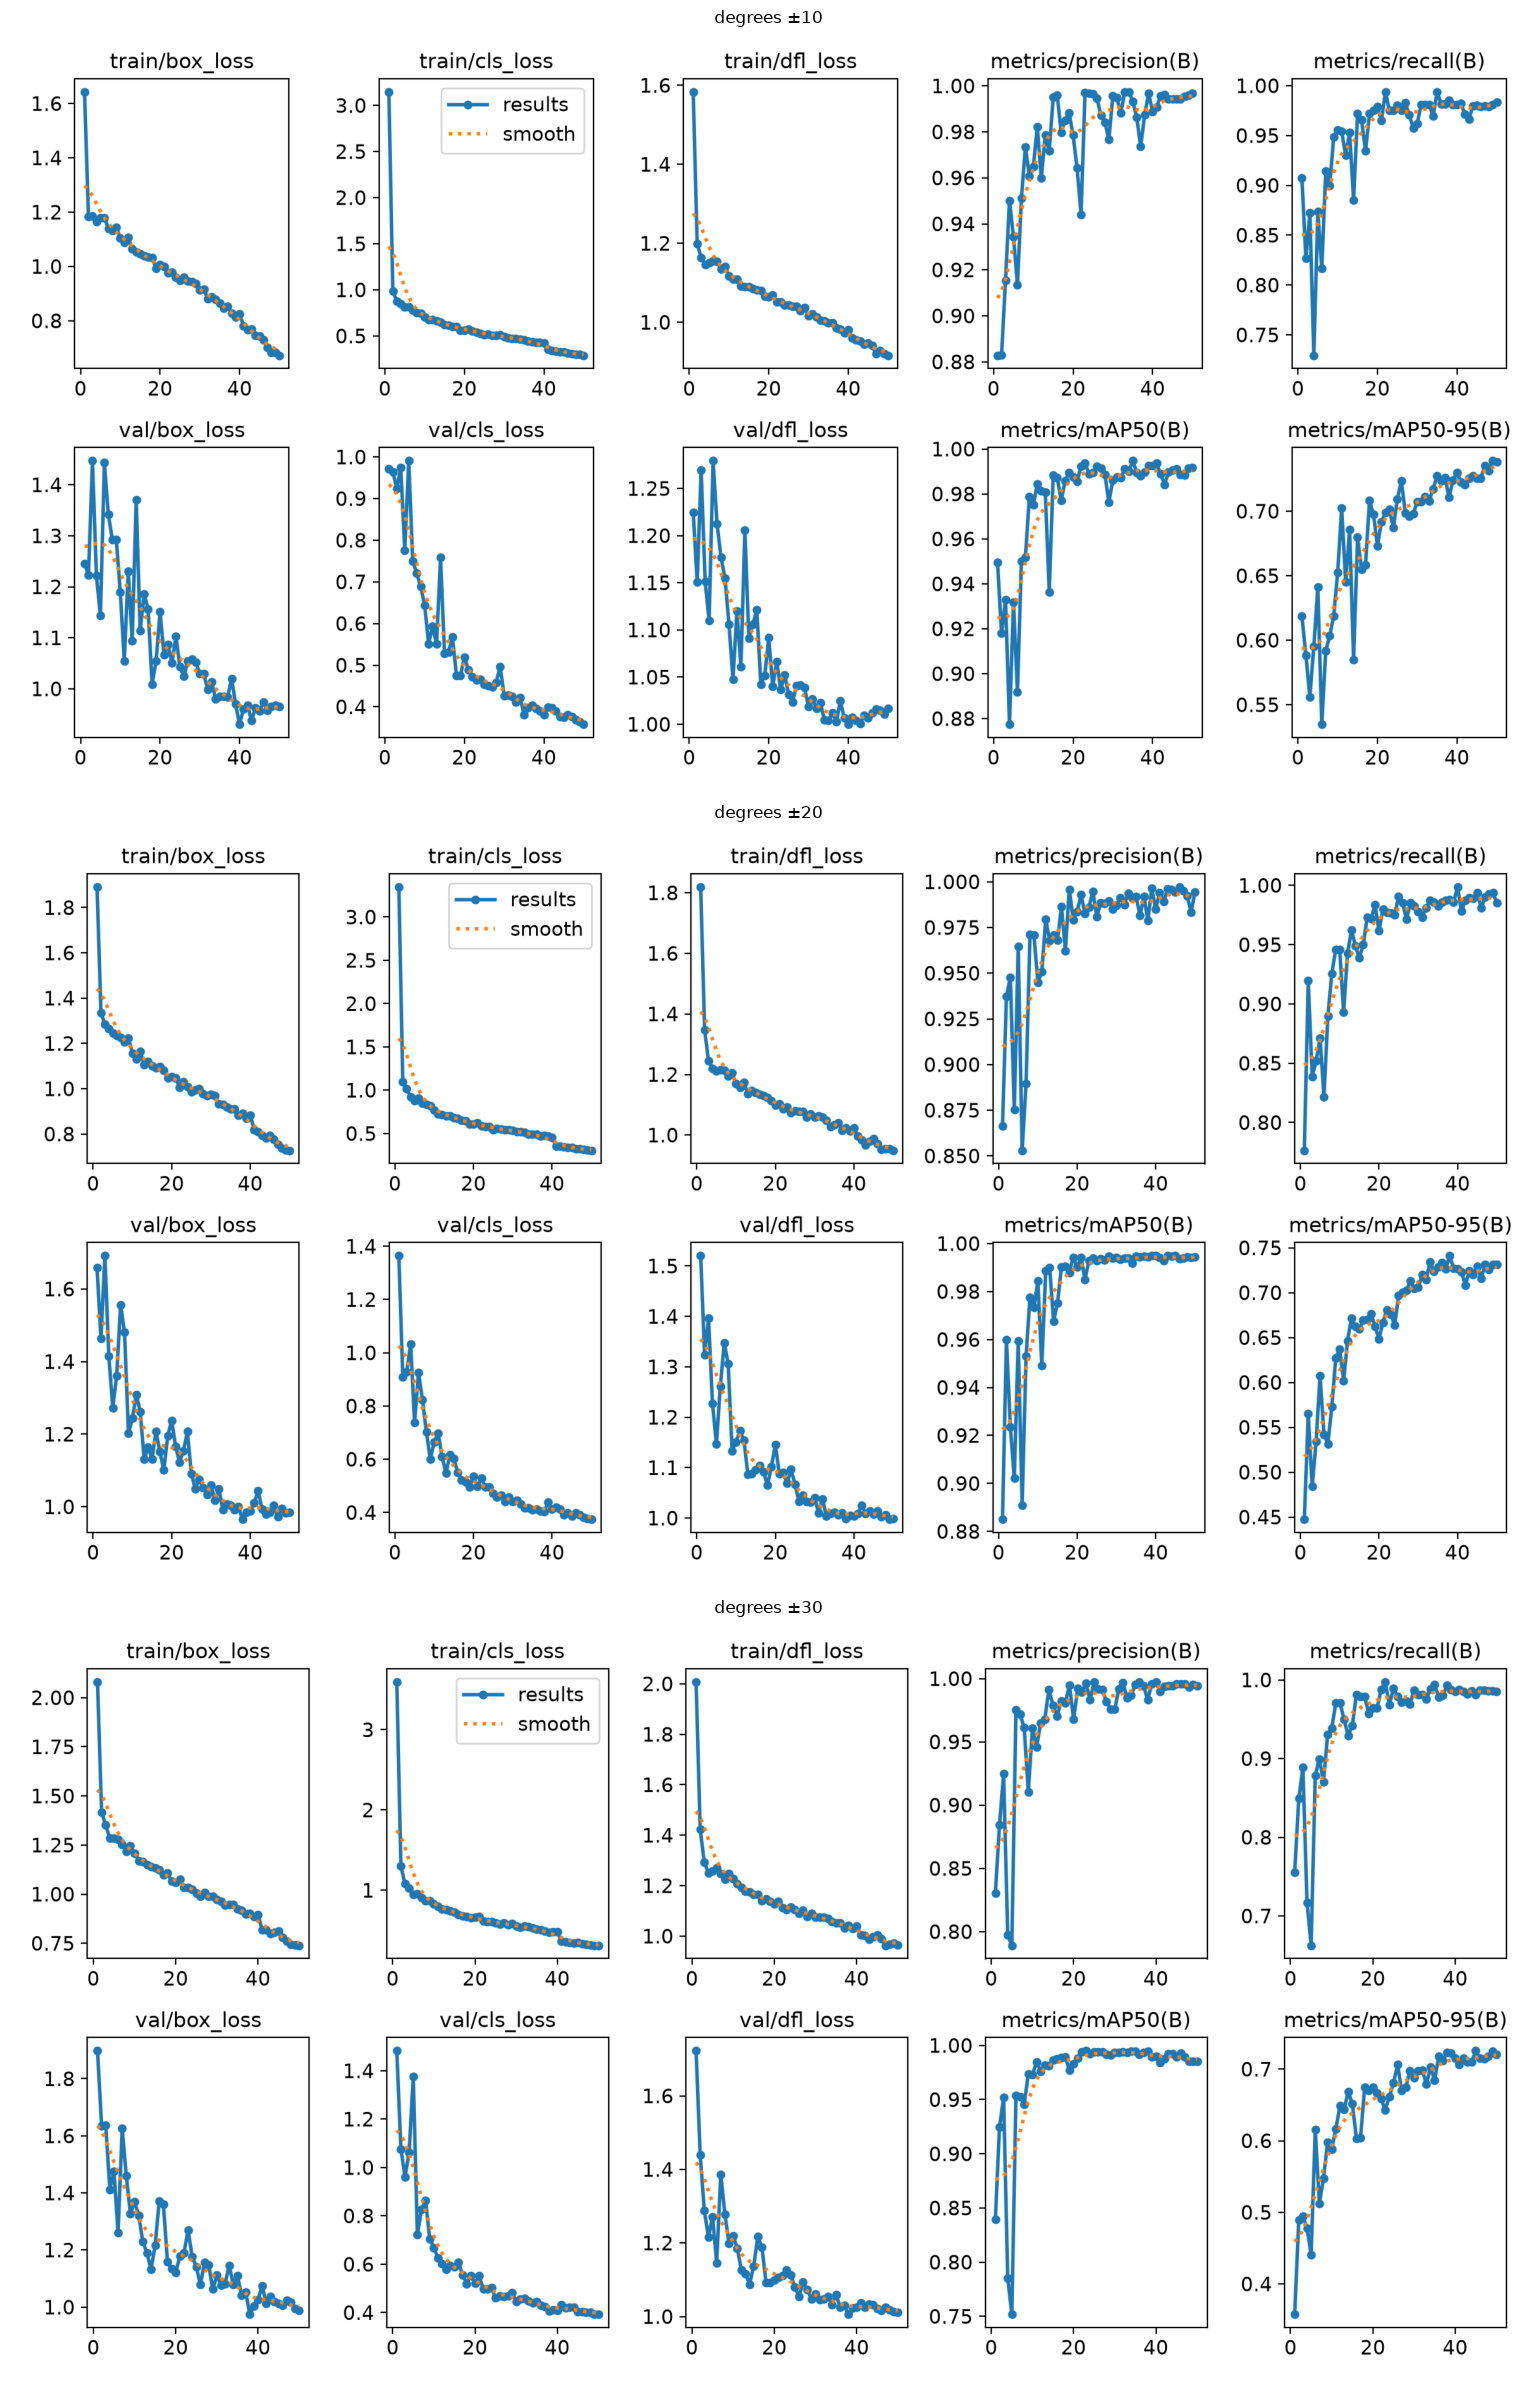

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.8))
h = pd.read_csv(ROOT / "results" / "baseline" / "results.csv"); h.columns = h.columns.str.strip()
ax.plot(h["epoch"], h["metrics/mAP50-95(B)"], lw=2.5, label="baseline (0°)")
for v in VALUES:
    h = pd.read_csv(ROOT / "results" / f"degrees_{v}" / "results.csv"); h.columns = h.columns.str.strip()
    line, = ax.plot(h["epoch"], h["metrics/mAP50-95(B)"], label=f"±{v}°")
    b = h["metrics/mAP50-95(B)"].idxmax(); ax.plot(h.loc[b, "epoch"], h.loc[b, "metrics/mAP50-95(B)"], "o", color=line.get_color())
ax.set(title="Validation mAP50-95", xlabel="epoch"); ax.grid(alpha=0.3); ax.legend(); plt.show()

fig, axes = plt.subplots(len(VALUES), 1, figsize=(16, 8 * len(VALUES)))
for ax, v in zip(axes, VALUES):
    ax.imshow(plt.imread(ROOT / "results" / f"degrees_{v}" / "results.png")); ax.set_title(f"degrees ±{v}"); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Evaluate the three new models
`evaluate()` gives the Ultralytics metrics on validation, full test and team-only test. `error_analysis()` scores the team photos at the deployment threshold (conf 0.25, IoU 0.5), including accuracy and the correct/incorrect example grids. The baseline was already scored the same way by the baseline notebook (`results/baseline/`).

In [5]:
for v in VALUES:
    name = f"degrees_{v}"
    overall, _ = evaluate(ROOT / "models" / f"{name}_best.pt", 640, ROOT / "results" / name)
    ea = error_analysis(ROOT / "models" / f"{name}_best.pt", 640, ROOT / "results" / name)
    print(name, {k: ea["summary"][k] for k in ["hands", "predictions", "correct", "precision", "recall", "F1", "accuracy"]})
    display(overall.round(4))

Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 2843.9±165.1 MB/s, size: 1295.5 KB)
val: Scanning C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\dataset\labels\val.cache... 160 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 160/160 95.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.6it/s 2.8s.2ss
                   all        160        160      0.996      0.981      0.993       0.74
Speed: 0.6ms preprocess, 3.0ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\runs\degrees_10_val
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 pa

,precision,recall,F1,mAP50,mAP50-95
validation (160),0.996,0.981,0.988,0.993,0.740
"test, all (160)",0.946,0.861,0.901,0.893,0.487
"test, team only (128)",0.925,0.828,0.874,0.863,0.436


Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 2604.2±583.8 MB/s, size: 1320.3 KB)
val: Scanning C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\dataset\labels\val.cache... 160 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 160/160 134.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.7it/s 2.7s.2ss
                   all        160        160      0.982      0.988      0.994      0.736
Speed: 0.6ms preprocess, 2.9ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\runs\degrees_20_val
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 p

,precision,recall,F1,mAP50,mAP50-95
validation (160),0.982,0.988,0.985,0.995,0.736
"test, all (160)",0.892,0.854,0.873,0.886,0.482
"test, team only (128)",0.890,0.821,0.854,0.856,0.433


Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 2820.6±97.0 MB/s, size: 1709.7 KB)
val: Scanning C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\dataset\labels\val.cache... 160 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 160/160 111.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.7it/s 2.7s.1ss
                   all        160        160      0.996       0.98      0.989      0.724
Speed: 0.6ms preprocess, 2.9ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\runs\degrees_30_val
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 pa

,precision,recall,F1,mAP50,mAP50-95
validation (160),0.996,0.980,0.988,0.989,0.724
"test, all (160)",0.937,0.866,0.900,0.913,0.508
"test, team only (128)",0.914,0.833,0.872,0.890,0.475


## 3. Comparison with the baseline (degrees 0)

In [6]:
RUNS = {0: "baseline", **{v: f"degrees_{v}" for v in [10, 20, 30]}}
summary = pd.DataFrame({name: {"degrees": v, **summary_row(ROOT / "results" / name)}
                        for v, name in sorted(RUNS.items())}).T.rename_axis("run")
summary.round(4).to_csv(ROOT / "results" / "tuning_degrees_summary.csv")
summary

,degrees,epochs_run,best_epoch,train_minutes,val mAP50,val mAP50-95,team P,team R,team F1,team mAP50,team mAP50-95,team fist mAP50,small-hand recall,P @ conf 0.25,R @ conf 0.25,F1 @ conf 0.25,accuracy @ conf 0.25
run,,,,,,,,,,,,,,,,,
baseline,0.0,50.0,41.0,15.3,0.990,0.748,0.894,0.775,0.830,0.845,0.418,0.625,0.562,0.838,0.805,0.821,0.697
degrees_10,10.0,50.0,49.0,8.7,0.993,0.740,0.925,0.828,0.874,0.863,0.436,0.677,0.625,0.903,0.851,0.876,0.780
degrees_20,20.0,50.0,38.0,8.3,0.995,0.736,0.890,0.821,0.854,0.856,0.433,0.729,0.688,0.843,0.838,0.840,0.725
degrees_30,30.0,50.0,45.0,8.2,0.989,0.724,0.914,0.833,0.872,0.890,0.475,0.739,0.625,0.852,0.857,0.854,0.746


### Change from the baseline (team-only test)
Positive = better than the baseline (degrees 0). Single-model differences under about ±0.06 team mAP50 are within the noise of our 128 photos (bootstrap, see the baseline report).

In [7]:
metric_cols = ["val mAP50", "val mAP50-95", "team P", "team R", "team F1", "team mAP50", "team mAP50-95",
               "team fist mAP50", "small-hand recall", "F1 @ conf 0.25", "accuracy @ conf 0.25"]
summary[metric_cols] = summary[metric_cols].astype(float)
(summary[metric_cols] - summary.loc["baseline", metric_cols]).drop("baseline").round(3)

,val mAP50,val mAP50-95,team P,team R,team F1,team mAP50,team mAP50-95,team fist mAP50,small-hand recall,F1 @ conf 0.25,accuracy @ conf 0.25
run,,,,,,,,,,,
degrees_10,0.003,-0.008,0.031,0.053,0.044,0.018,0.018,0.052,0.063,0.055,0.083
degrees_20,0.005,-0.011,-0.004,0.046,0.024,0.011,0.015,0.104,0.126,0.019,0.028
degrees_30,-0.001,-0.024,0.020,0.058,0.042,0.046,0.057,0.114,0.063,0.033,0.049


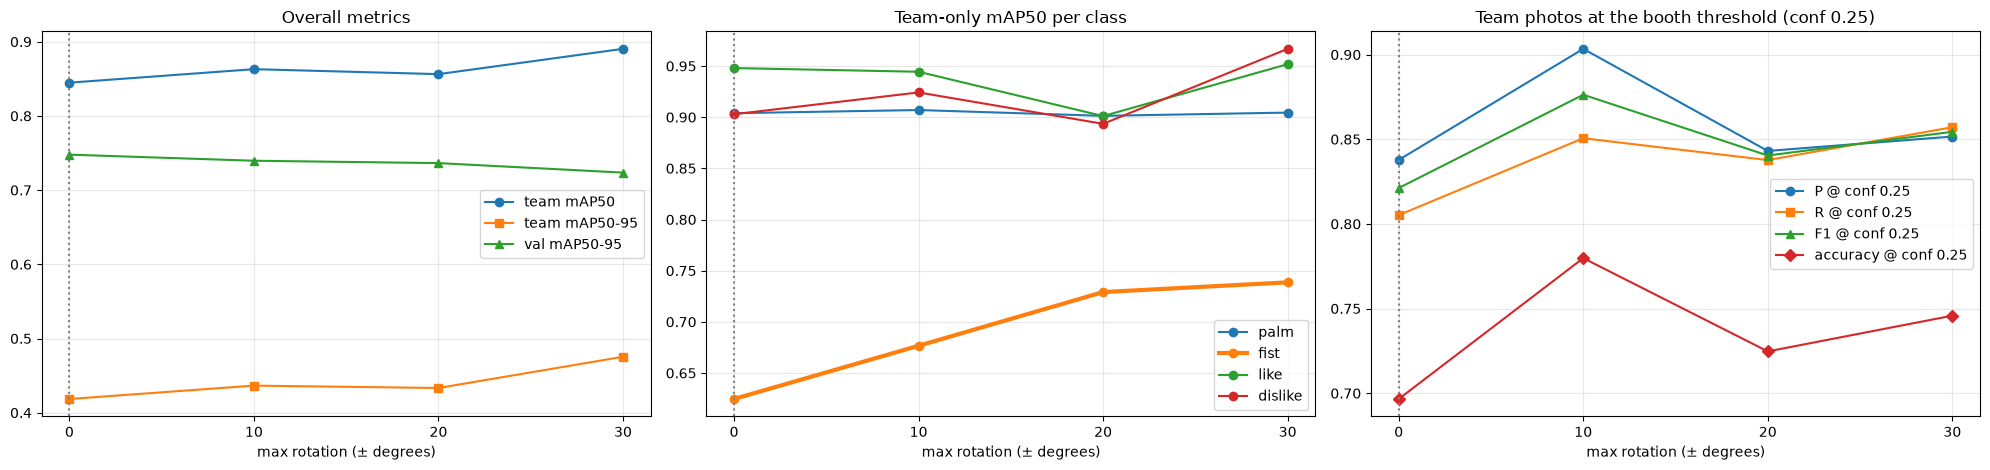

In [8]:
xs = sorted(RUNS)
names = [RUNS[x] for x in xs]
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))

ax = axes[0]
for col, mk in [("team mAP50", "o"), ("team mAP50-95", "s"), ("val mAP50-95", "^")]:
    ax.plot(xs, summary.loc[names, col], marker=mk, label=col)
ax.set_title("Overall metrics"); ax.legend()

ax = axes[1]
pc = pd.DataFrame({x: pd.read_csv(ROOT / "results" / RUNS[x] / "per_class.csv", index_col=[0, 1])
                   .loc["test (team only)", "mAP50"] for x in xs}).loc[CLASSES]
for c in CLASSES:
    ax.plot(xs, pc.loc[c, xs], marker="o", lw=3 if c == "fist" else 1.5, label=c)
ax.set_title("Team-only mAP50 per class"); ax.legend()

ax = axes[2]
for col, mk in [("P @ conf 0.25", "o"), ("R @ conf 0.25", "s"), ("F1 @ conf 0.25", "^"), ("accuracy @ conf 0.25", "D")]:
    ax.plot(xs, summary.loc[names, col], marker=mk, label=col)
ax.set_title("Team photos at the booth threshold (conf 0.25)"); ax.legend()

for ax in axes:
    ax.set_xlabel("max rotation (± degrees)"); ax.set_xticks(xs); ax.grid(alpha=0.3); ax.axvline(0, color="grey", ls=":")
plt.tight_layout()
fig.savefig(ROOT / "results" / "tuning_degrees_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

### The hands the baseline missed
For every team-photo hand the baseline got wrong at conf 0.25: what each `degrees` model predicted for it (`team_hands.csv`).

In [9]:
key = ["file", "gt_index"]
team_hands = {x: pd.read_csv(ROOT / "results" / RUNS[x] / "team_hands.csv") for x in xs}
base = team_hands[[x for x in xs if RUNS[x] == "baseline"][0]]
wrong = base.loc[~base["correct"], key + ["person", "class", "area_frac"]].copy()
wrong["area %"] = (wrong.pop("area_frac") * 100).round(2)
for x in xs:
    if RUNS[x] != "baseline":
        wrong[RUNS[x]] = wrong.merge(team_hands[x], on=key, how="left")["pred_class"].values
fixed = {RUNS[x]: int((wrong[RUNS[x]] == wrong["class"]).sum()) for x in xs if RUNS[x] != "baseline"}
broke = {RUNS[x]: int((base["correct"].values & ~team_hands[x]["correct"].values).sum()) for x in xs if RUNS[x] != "baseline"}
print(f"baseline errors: {len(wrong)} | fixed: {fixed} | newly wrong: {broke}")
wrong.sort_values("area %").reset_index(drop=True)

baseline errors: 30 | fixed: {'degrees_10': 12, 'degrees_20': 14, 'degrees_30': 14} | newly wrong: {'degrees_10': 5, 'degrees_20': 9, 'degrees_30': 6}


,file,gt_index,person,class,area %,degrees_10,degrees_20,degrees_30
0,dislike_385.jpg,0,Daff,dislike,0.16,missed,missed,missed
1,fist_370.jpg,3,Amy,fist,0.26,missed,missed,missed
2,fist_370.jpg,2,Amy,fist,0.29,fist,missed,missed
3,fist_398.jpg,0,Joseph,fist,0.54,fist,fist,fist
4,like_372.jpg,1,Amy,like,0.68,missed,like,like
5,like_372.jpg,0,Amy,like,0.72,palm,fist,missed
6,fist_390.jpg,0,Daff,fist,0.89,missed,fist,missed
7,like_373.jpg,1,Amy,like,1.22,missed,missed,missed
8,fist_376.jpg,1,Amy,fist,1.38,fist,fist,fist
9,dislike_375.jpg,1,Amy,dislike,1.59,dislike,dislike,dislike


### Correct and incorrect examples
`error_analysis()` saves both grids for every run (`results/degrees_<value>/correct_cases.jpg` and `failure_cases.jpg`). Green boxes are the labels, red boxes are predictions at conf 0.25. Shown here for the best run by team mAP50.

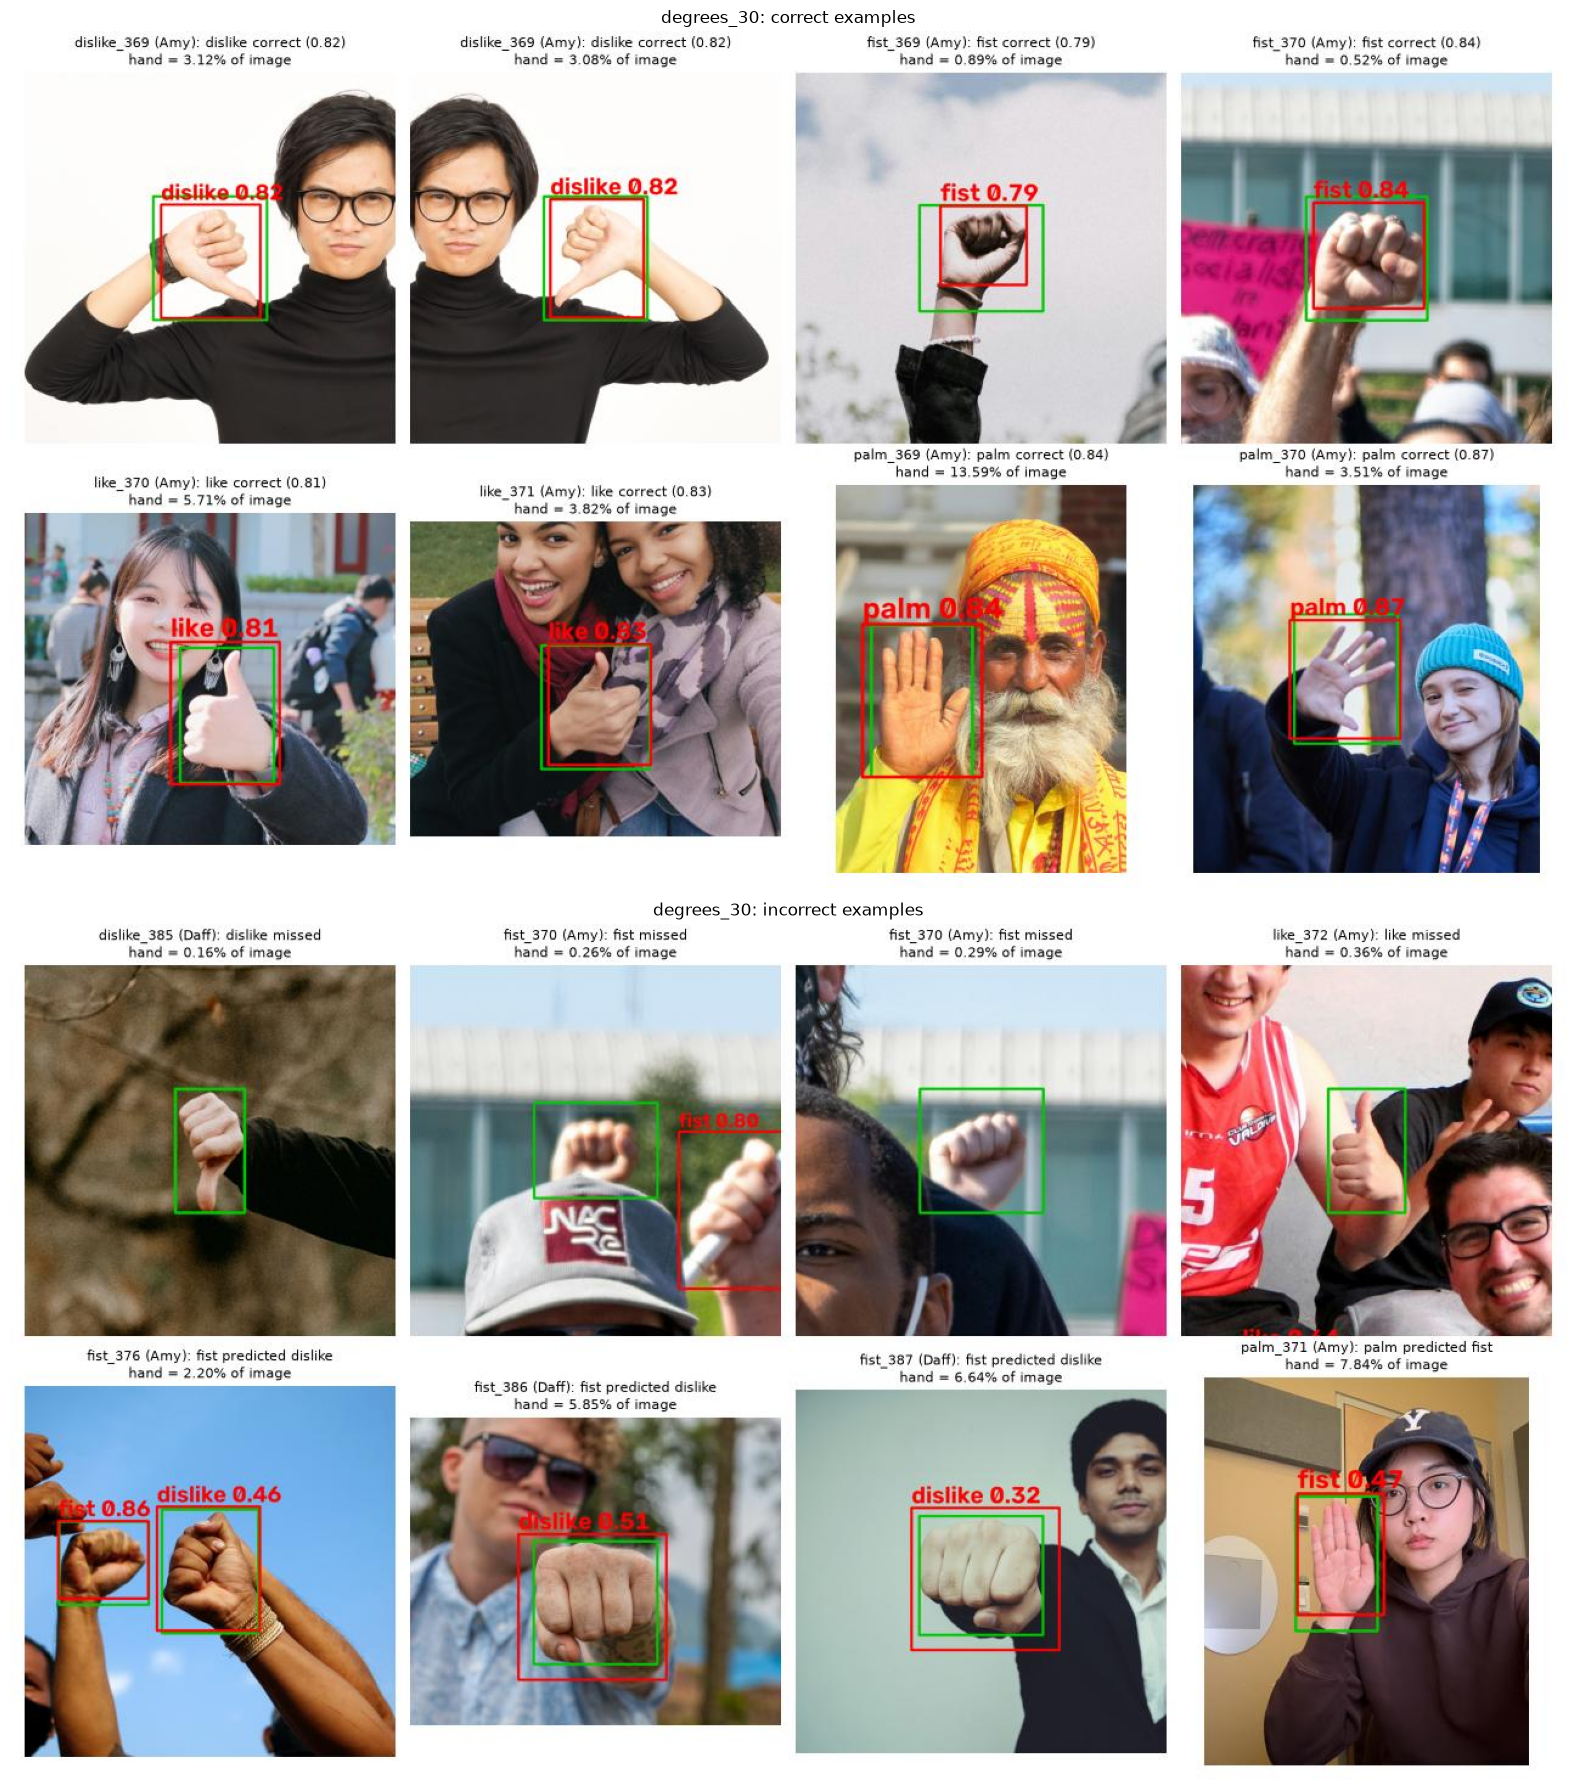

In [10]:
best_run = summary.drop("baseline")["team mAP50"].astype(float).idxmax()
fig, axes = plt.subplots(2, 1, figsize=(16, 18))
for ax, f, title in zip(axes, ["correct_cases.jpg", "failure_cases.jpg"], ["correct", "incorrect"]):
    ax.imshow(plt.imread(ROOT / "results" / best_run / f)); ax.set_title(f"{best_run}: {title} examples"); ax.axis("off")
plt.tight_layout(); plt.show()

### 3.1 Side effects: like ↔ dislike confusion and box tightness
Per-class recall on the team photos at conf 0.25, the number of thumbs-up predicted as thumbs-down (and the reverse), and the mean IoU of correct detections (how tightly the predicted boxes fit our labels).

In [11]:
rows = {}
for x in xs:
    d = ROOT / "results" / RUNS[x]
    h = pd.read_csv(d / "team_hands.csv")
    rows[RUNS[x]] = {
        **{f"{c} recall": h.loc[h["class"] == c, "correct"].mean() for c in CLASSES},
        "like -> dislike": int(((h["class"] == "like") & (h["pred_class"] == "dislike")).sum()),
        "dislike -> like": int(((h["class"] == "dislike") & (h["pred_class"] == "like")).sum()),
        "mean IoU (correct)": json.loads((d / "error_analysis.json").read_text())["mean_IoU_correct"],
        "team mAP50-95": summary.loc[RUNS[x], "team mAP50-95"],
    }
pd.DataFrame(rows).T.astype(float).round(3)

,palm recall,fist recall,like recall,dislike recall,like -> dislike,dislike -> like,mean IoU (correct),team mAP50-95
baseline,0.758,0.639,0.929,0.860,0.0,0.0,0.763,0.418
degrees_10,0.939,0.694,0.881,0.884,0.0,0.0,0.771,0.436
degrees_20,0.909,0.750,0.857,0.837,0.0,0.0,0.771,0.433
degrees_30,0.939,0.694,0.833,0.953,0.0,0.0,0.776,0.475


## 4. Discussion
_Filled in after the runs._